# Lab 2.1 · Choosing an inference instance

**15–20 minutes · CPU · Python standard library**

Read the worked example, then run the setup. For each exercise, make a prediction, implement the function, and run the check. [Open the lab guide](README.md) for the reading and setup instructions.

A GPU spec sheet answers different questions. **Dense compute throughput** gives a peak rate at a stated precision. Use the dense figures at the workload's precision. An FP8 result and a sparse BF16 rating are different operating points. **Memory capacity** controls what can fit, while **memory bandwidth** describes how quickly data can be moved within the GPU. Neither predicts request latency by itself.

A **MIG partition** exposes a profile with its own compute and memory resources. Read the profile's usable memory directly. Fit requires space for weights, the request state, and runtime allocations. For a conventional decoder KV cache, count two arrays (K and V) per layer, with one vector per KV head at each cached token. A batch of unequal-length requests uses the sum of their cached token counts in this packed estimate. Alignment, allocation blocks, and runtime buffers can raise the actual requirement.

A multi-GPU deployment also has to move data between devices. Convert the effective one-way link rate to bytes per second before estimating a transfer floor. For example, 80 Gb/s is 10 GB/s, so a 20 MB payload takes at least 2 ms at that rate. A real collective can add synchronization, extra data movement, and contention. A link's peak rating also depends on how bandwidth is quoted.

The profiles and workload sizes in this lab are fictional, fixed inputs. They let you isolate the decisions without hardware access, live prices, or model downloads. All GB, MB, and link rates use decimal units.

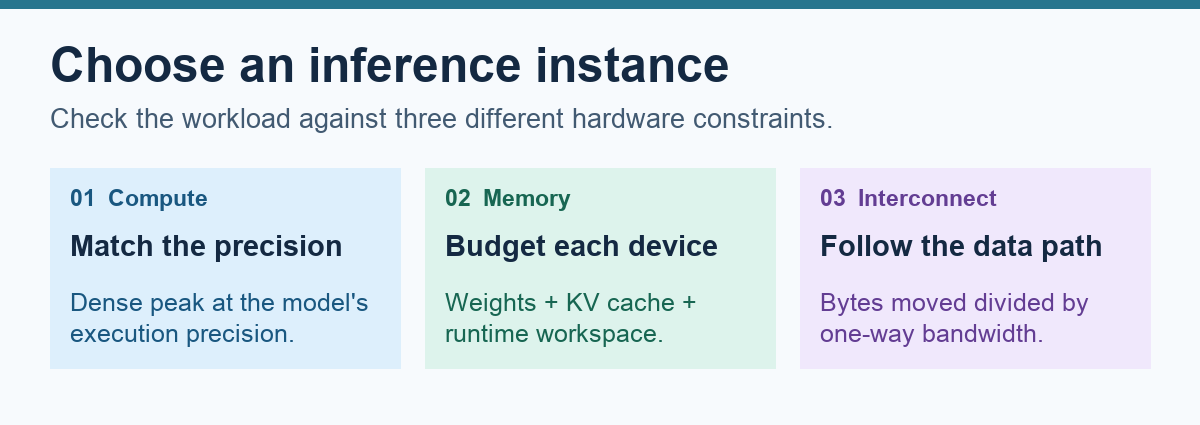

## Exercise map

| Exercise | What you will do | What to look for |
| --- | --- | --- |
| 1. Compare compute quotes | Select the dense BF16 figures from two spec sheets. | An FP8 or sparse peak can reverse the ranking. |
| 2. Size a replica | Account for weights, workspace, and KV cache at two concurrency levels. | A partition can fit the short workload and run out of memory on the longer one. |
| 3. Check a multi-GPU path | Normalize bandwidth units and estimate a transfer floor for two links. | Identical accelerator layouts can have different communication costs. |

In [ ]:
from math import isclose

GB = 10**9
MB = 10**6
profiles = {
    "A": {"BF16": {"dense": 110, "sparse": 220}, "FP8": {"dense": 220}},
    "B": {"BF16": {"dense": 140, "sparse": 280}, "FP8": {"dense": 280}},
}
for name, quotes in profiles.items():
    print(name, quotes, "TFLOP/s")

## Exercise 1. Compare the right compute figures

The runtime uses dense BF16. Select the dense quote at the requested precision. Predict which candidate leads after filtering. As a sanity check, compare A's FP8 number with B's BF16 number and explain how mixing precisions leads to a different choice.

In [ ]:
def dense_peak(quotes, precision):
    return None

In [ ]:
peaks = {name: dense_peak(quotes, "BF16") for name, quotes in profiles.items()}
if any(value is None for value in peaks.values()):
    print("Complete dense_peak and rerun this check.")
else:
    assert peaks == {"A": 110, "B": 140}
    assert dense_peak(profiles["A"], "FP8") == 220
    print("PASS — matched BF16 peaks in TFLOP/s:", peaks)

## Exercise 2. Calculate the replica's memory margin

The model uses 14 GB for weights and reserves 2 GB for runtime workspace. Its BF16 KV cache has 32 layers, 8 KV heads, and 128 elements per head. A single cached token needs `2 × 32 × 8 × 128 × 2` bytes. For each scenario, multiply by the total cached tokens across active requests and subtract all allocations from the profile's usable bytes.

A full GPU exposes 48 GB and a partition exposes 20 GB for this exercise. Compare two workloads. Use a list of request lengths so your calculation works for mixed contexts too.

In [ ]:
def memory_margin(usable_bytes, weights_bytes, workspace_bytes, context_lengths,
                  layers=32, kv_heads=8, head_width=128, bytes_per_value=2):
    return None

In [ ]:
short = [2048] * 4
long = [8192] * 8
probe = memory_margin(GB, 0, 0, [1])
if probe is None:
    print("Complete memory_margin and rerun this check.")
else:
    assert probe == GB - 131_072
    assert memory_margin(GB, 0, 0, [1, 3]) == GB - 4 * 131_072
    margins = {}
    print(f"{'Profile':<12} {'Short (GB)':>12} {'Long (GB)':>12}")
    for name, capacity in [("Partition", 20 * GB), ("Full GPU", 48 * GB)]:
        margins[name] = [memory_margin(capacity, 14 * GB, 2 * GB, lengths)
                         for lengths in (short, long)]
        a, b = margins[name]
        print(f"{name:<12} {a / GB:12.3f} {b / GB:12.3f}")
    assert margins["Partition"][0] > 0 > margins["Partition"][1]
    assert all(value > 0 for value in margins["Full GPU"])
    print("PASS — the longer workload exceeds the partition's modeled capacity")

### Read the result

The weights stay fixed across both scenarios. The KV cache grows from the total cached tokens, which here rises from 8,192 to 65,536. A negative margin gives you a reason to reject the profile even before benchmarking.

## Exercise 3. Compare two multi-GPU links

A different model is already sharded across two GPUs, and each shard fits its device. On the modeled critical path, a step must move 100 MB once between GPUs. One candidate provides a 64 GB/s one-way path; another reports 200 Gb/s. Convert the rates so you can compare units. Return the transfer floor in milliseconds and check each path against a 2 ms communication budget.

Assume the full quoted one-way rate is available to the transfer. In a real trace, account for synchronization and any other transfers on the critical path.

In [ ]:
def transfer_ms(payload_bytes, rate, unit):
    return None

In [ ]:
links = [(64, "GB/s"), (200, "Gb/s")]
times = [transfer_ms(100 * MB, rate, unit) for rate, unit in links]
if any(value is None for value in times):
    print("Complete transfer_ms and rerun this check.")
else:
    assert isclose(transfer_ms(GB, 8, "Gb/s"), 1000)
    assert all(isclose(a, b) for a, b in zip(times, [1.5625, 4.0]))
    for (rate, unit), time in zip(links, times):
        print(f"{rate:3} {unit}: {time:.3f} ms floor, fits budget: {time <= 2}")
    print("PASS — the 200 Gb/s path already exceeds the budget at its floor")

## Make the recommendation

1. Pick a profile for the short and long workloads. What peak-memory measurement would you ask for before running the service?
2. Which two-GPU path would you investigate first? Estimate what fraction of the 2 ms budget is left after the modeled transfer.
3. To compare serving performance, record the model, precision, runtime, context distribution, and concurrency. Report time to first token and inter-token latency alongside throughput, and check whether the device actually saturates its link or memory bandwidth.

**Reading** · Philip Kiely, *Inference Engineering*, §§3.1–3.3, pp. 74–87.